# 问题描述

Using Python/C/C++/Fortran, write a finite element code to evaluate the response of truss systems.

1. Your program should read a file named input that contains any useful information.

2. Your program should produce a file named output that contains the following information and outputs:Using your completed code, solve the truss problem shown in Figure 1 for $P=6000 N$ and obtain the deformed shape of the structure (plot the deformed shape overlaid with the undeformed shape in your report). What and where are the maximum vertical displacement, the maximum compressive stress, and the maximum tensile stress? Provide the values of the reactions at the two support nodes.

3. Your codes should be easy enough to follow. Here are some ways to improve the readability of your codes:
    1) Put comments as much as you can!
    2) Perform different parts of your finite element analysis in different modules and then call the modules in the main body of your code. For example, write separate modules for reading the input file, initialization of equations, assembly of different vectors and matrices, solving the equation systems, and writing the output file.

4. Use your code to obtain the response of the example truss system given below:

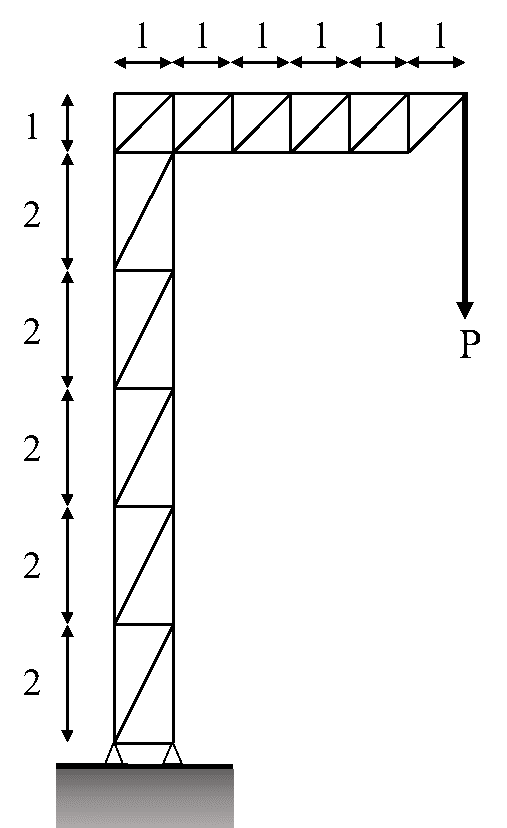

Figure 1 The truss example to be solved using the completed code. The vertical and horizontal segments of the crane are made of aluminum (Young’s modulus $E=60 GPa$, and have a cross-section of $2 cm^2$. The diagonal truss elements are made of steel (Young’s modulus $E=200 GPa$, and have a cross-section of $3 cm^2$. The structure is subjected to a load $P=6000 N$ applied as illustrated in the figure. The two support nodes are assumed fixed (i.e., x- and y-displacements are 0).

5. Email your code named Student_ID-Name-Project1.zip the TA for testing. Also, prepare a short report on what different modules of your code do. Attach to your report the input file for the example truss system given in part (4) as well as the output file you will obtain from running the code for that example. Hand in the hardcopy of your report in class.


# 前置处理

## 导入python第三方库

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import math

## 定义Element类

In [2]:
# 定义Element类，存储单元节点编号，单元的弹性模量、横截面积和长度信息
class Element:
    def __init__(self, n1, n2, stiff, S, L):
        self.node1 = n1
        self.node2 = n2
        self.stiffness = stiff
        self.area = S
        self.length = L

    # 生成k_e矩阵
    def Matrix(self, node):
        c = (node[self.node2 - 1][0] - node[self.node1 - 1][0]) / self.length
        s = (node[self.node2 - 1][1] - node[self.node1 - 1][1]) / self.length
        k = self.stiffness * self.area / self.length
        matrix = np.array(
            [
                [c**2, s * c, -(c**2), -s * c],
                [s * c, s**2, -s * c, -(s**2)],
                [-(c**2), -s * c, c**2, s * c],
                [-s * c, -(s**2), s * c, s**2],
            ]
        )
        matrix[:4, :4] *= k
        return matrix

    # 计算应变
    def Axial_stress(self, nodes, nodes_after):
        delta_length = math.sqrt(
            (nodes_after[self.node1 - 1][0] - nodes_after[self.node2 - 1][0]) ** 2
            + (nodes_after[self.node1 - 1][1] - nodes_after[self.node2 - 1][1]) ** 2
        ) - math.sqrt(
            (nodes[self.node1 - 1][0] - nodes[self.node2 - 1][0]) ** 2
            + (nodes[self.node1 - 1][1] - nodes[self.node2 - 1][1]) ** 2
        )
        strain = delta_length / self.length
        return self.stiffness * strain

## 读取文件

In [7]:
# 存储材料属性
material = [{}, {}, {}, {}]
# 存储杆单元
element = []
# 存储节点信息
nodes = []

with open("../../input/Truss 1.txt", "r") as f:
    lines = f.readlines()
    # 读取不同杆件的力学参数
    for i in range(4):
        tmp = lines[i].strip().split(" ")
        material[i] = {
            "stiffness": float(tmp[0]),
            "area": float(tmp[1]),
            "length": float(tmp[2]),
        }
    # 读取外力P
    F = lines[4].strip()
    # 将杆件的信息存储到element列表内
    for i in range(5, 48):
        element.append(
            Element(
                int(lines[i].strip().split(" ")[0]),
                int(lines[i].strip().split(" ")[1]),
                material[int(lines[i].strip().split(" ")[2]) - 1]["stiffness"],
                material[int(lines[i].strip().split(" ")[2]) - 1]["area"],
                material[int(lines[i].strip().split(" ")[2]) - 1]["length"],
            )
        )
    # 读取节点坐标
    for i in range(48, 71):
        nodes.append(
            [int(lines[i].strip().split(" ")[0]), int(lines[i].strip().split(" ")[1])]
        )

# 问题求解

## 装配全局刚度矩阵$[K]$

In [8]:
# 创建空矩阵
stiffnessMatrix = np.zeros((46, 46))
vector = np.zeros(4)

# 按杆进行全局刚度矩阵的装配
for bar in element:
    vector = [2 * bar.node1 - 1, 2 * bar.node1, 2 * bar.node2 - 1, 2 * bar.node2]
    for i in range(4):
        for j in range(4):
            stiffnessMatrix[vector[i] - 1][vector[j] - 1] += bar.Matrix(nodes)[i][j]
print(stiffnessMatrix)
print(np.linalg.det(stiffnessMatrix[-42:, -42:]))

[[ 12000000.                 0.         -12000000.         ...
          0.                 0.                 0.        ]
 [        0.           6000000.                 0.         ...
          0.                 0.                 0.        ]
 [-12000000.                 0.          17366563.14959798 ...
          0.                 0.                 0.        ]
 ...
 [        0.                 0.                 0.         ...
   33213203.45238569 -21213203.45238569 -21213203.45238569]
 [        0.                 0.                 0.         ...
  -21213203.45238569  33213203.45238569  21213203.45238569]
 [        0.                 0.                 0.         ...
  -21213203.45238569  21213203.45238569  21213203.45238569]]
1.128333376922544e+294


## 求解控制方程
$\{F\}=[K]\{U\}$

In [9]:
# 初始化F_a、F_c、U_c矩阵
F_aMatrix = np.zeros(42).T
F_aMatrix[41] = F
U_cMatrix = np.zeros(4).T

# 初始化U_a矩阵
U_aMatrix = np.dot(
    np.linalg.inv(stiffnessMatrix[-42:, -42:]),
    (F_aMatrix - np.dot(stiffnessMatrix[-42:, :4], U_cMatrix)),
)
print(U_aMatrix)

# 初始化F_c矩阵
F_cMatrix = np.dot(stiffnessMatrix[:4, :4], U_cMatrix) + np.dot(
    stiffnessMatrix[:4, -42:], U_aMatrix
)
print(F_cMatrix)

# 节点位移
nodes_delta = []
nodes_delta = np.concatenate((U_cMatrix.T, U_aMatrix.T))
print(nodes_delta)

# 节点力
nodes_force = []
nodes_force = np.concatenate((F_cMatrix.T, F_aMatrix.T))
print(nodes_force)

# 节点变形后坐标
nodes_after = []
for i in range(23):
    x = nodes[i][0] - nodes_delta[2 * i]
    y = nodes[i][1] - nodes_delta[2 * i + 1]
    nodes_after.append([x, y])

[-0.012      -0.005      -0.012       0.006      -0.046       0.012
 -0.046      -0.01       -0.102      -0.015      -0.102       0.018
 -0.18        0.024      -0.18       -0.02       -0.2825     -0.025
 -0.34141421 -0.025      -0.34141421  0.0325     -0.28        0.03
 -0.278       0.09469706 -0.34391421  0.09419706 -0.34591421  0.16289411
 -0.2765      0.16339411 -0.2755      0.23509117 -0.34741421  0.23459117
 -0.34841421  0.30828823 -0.275       0.30878823 -0.34891421  0.38298528]
[ 0.0000000e+00 -3.6000000e+04  1.1496013e-09  3.0000000e+04]
[ 0.          0.          0.          0.         -0.012      -0.005
 -0.012       0.006      -0.046       0.012      -0.046      -0.01
 -0.102      -0.015      -0.102       0.018      -0.18        0.024
 -0.18       -0.02       -0.2825     -0.025      -0.34141421 -0.025
 -0.34141421  0.0325     -0.28        0.03       -0.278       0.09469706
 -0.34391421  0.09419706 -0.34591421  0.16289411 -0.2765      0.16339411
 -0.2755      0.23509117 -0.34

## 计算节点位移、最大拉压应力等

In [10]:
# 最大垂直位移
Maximum_vertical_displacement = {
    "value": np.max(nodes_delta[1::2]),
    "ID": int((np.argwhere(nodes_delta == np.max(nodes_delta[1::2])) + 1)[0][0] / 2),
}
print(Maximum_vertical_displacement)

# 最大压应力和最大拉应力
stress = []
for bar in element:
    stress.append(bar.Axial_stress(nodes, nodes_after))

Maximum_tensile_stress = {
    "value": np.max(stress),
    "ID": int((np.argwhere(stress == np.max(stress)) + 1)[0][0]),
}
Minimum_tensile_stress = {
    "value": np.min(stress),
    "ID": int((np.argwhere(stress == np.min(stress)) + 1)[0][0]),
}
print(Maximum_tensile_stress)
print(Minimum_tensile_stress)

# 支座反力
Support_reaction = [
    {"F_x": F_cMatrix[0], "F_y": F_cMatrix[1]},
    {"F_x": F_cMatrix[2], "F_y": F_cMatrix[3]},
]
print(Support_reaction)

{'value': np.float64(0.3829852813675775), 'ID': 23}
{'value': np.float64(519466820.769314), 'ID': 43}
{'value': np.float64(-178916760.0586339), 'ID': 2}
[{'F_x': np.float64(0.0), 'F_y': np.float64(-36000.00000001021)}, {'F_x': np.float64(1.1496013030409813e-09), 'F_y': np.float64(30000.00000000855)}]


# 求解可视化

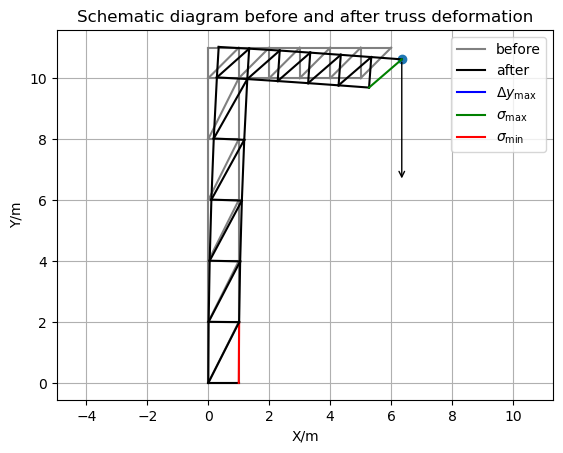

In [11]:
# 变形前节点的位置
x_0 = [node[0] for node in nodes]
y_0 = [node[1] for node in nodes]

# 变形后节点的位置
x_1 = [node[0] for node in nodes_after]
y_1 = [node[1] for node in nodes_after]

fig, ax = plt.subplots()

# 绘制散点图
# ax.scatter(x_0, y_0)
# ax.scatter(x_1, y_1)

# 连线
for bar in element:
    ax.plot(
        [x_0[bar.node1 - 1], x_0[bar.node2 - 1]],
        [y_0[bar.node1 - 1], y_0[bar.node2 - 1]],
        "gray",
        label="before",
    )
for bar in element:
    if element.index(bar) == Maximum_tensile_stress["ID"] - 1:
        ax.plot(
            [x_1[bar.node1 - 1], x_1[bar.node2 - 1]],
            [y_1[bar.node1 - 1], y_1[bar.node2 - 1]],
            "green",
            label="max stress",
        )
    elif element.index(bar) == Minimum_tensile_stress["ID"] - 1:
        ax.plot(
            [x_1[bar.node1 - 1], x_1[bar.node2 - 1]],
            [y_1[bar.node1 - 1], y_1[bar.node2 - 1]],
            "red",
            label="min stress",
        )
    else:
        ax.plot(
            [x_1[bar.node1 - 1], x_1[bar.node2 - 1]],
            [y_1[bar.node1 - 1], y_1[bar.node2 - 1]],
            "black",
            label="after",
        )

ax.scatter(
    nodes_after[Maximum_vertical_displacement["ID"] - 1][0],
    nodes_after[Maximum_vertical_displacement["ID"] - 1][1],
)
arrow_props = dict(facecolor="red", arrowstyle="->")
ax.annotate(
    "",
    xy=(nodes_after[-1][0], nodes_after[-1][1] - 4),
    xytext=(nodes_after[-1][0], nodes_after[-1][1]),
    arrowprops=arrow_props,
)

# 设置坐标轴比例相同
ax.axis("equal")

ax.set_xlabel("X/m")
ax.set_ylabel("Y/m")
ax.grid()

ax.set_title("Schematic diagram before and after truss deformation")
plt.legend(
    handles=[
        plt.Line2D([], [], color="gray", label="before"),
        plt.Line2D([], [], color="black", label="after"),
        plt.Line2D([], [], color="blue", label="$\Delta y_{\max}$"),
        plt.Line2D([], [], color="green", label="$\sigma_{\max}$"),
        plt.Line2D([], [], color="red", label="$\sigma_{\min}$"),
    ]
)

plt.savefig("../../output/Truss 1/output.png")
plt.show()

# 生成output.txt

In [12]:
with open("../../output/Truss 1/output.txt", "w") as f:
    f.write(
        "NODE"
        + "\t"
        + "U_x".ljust(15)
        + "\t"
        + "U_y".ljust(15)
        + "\t"
        + "F_x".ljust(15)
        + "\t"
        + "F_y".ljust(15)
        + "\n"
    )
    for node in nodes_after:
        f.write(
            str(nodes_after.index(node) + 1).ljust(4)
            + "\t"
            + str(nodes_delta[2 * nodes_after.index(node)])[:9].ljust(15)
            + "\t"
            + str(nodes_delta[2 * nodes_after.index(node)])[:9].ljust(15)
            + "\t"
            + str(nodes_force[2 * nodes_after.index(node)])[:9].ljust(15)
            + "\t"
            + str(nodes_force[2 * nodes_after.index(node) + 1])[:9].ljust(15)
            + "\n"
        )
    f.write(
        "Maximum vertical displacement:"
        + "\n"
        + "number:".ljust(9)
        + str(Maximum_vertical_displacement["ID"]).ljust(15)
        + "value:".ljust(9)
        + str(Maximum_vertical_displacement["value"])[:9].ljust(15)
        + "\n"
        + "Maximum tensile stress:"
        + "\n"
        + "number:".ljust(9)
        + str(Maximum_tensile_stress["ID"]).ljust(15)
        + "value:".ljust(9)
        + str(Maximum_tensile_stress["value"])[:9].ljust(15)
        + "\n"
        + "Maximum compressive stress:"
        + "\n"
        + "number:".ljust(9)
        + str(Minimum_tensile_stress["ID"]).ljust(15)
        + "value:".ljust(9)
        + str(Minimum_tensile_stress["value"])[:9].ljust(15)
        + "\n"
        + "Reaction forces at support nodes:"
        + "\n"
        + "F_x1:".ljust(9)
        + str(Support_reaction[0]["F_x"])[:9].ljust(15)
        + "F_y1:".ljust(9)
        + str(Support_reaction[0]["F_y"])[:9].ljust(15)
        + "\n"
        + "F_x2:".ljust(9)
        + str(Support_reaction[1]["F_x"])[:9].ljust(15)
        + "F_y2:".ljust(9)
        + str(Support_reaction[1]["F_y"])[:9].ljust(15)
    )

# 结论分析

通过编写简单的有限元程序求解二维桁架的变形使我对有限元方法的便捷性有了更新的认识。经过对比程序运算的结果与弹性力学理论解，可以得出相同的结果。程序求解的最大拉压应力和最大垂直位移符合一般的力学规律。